### Apartado 6: Machine Learning

**Objetivo**: estimar el **retraso de llegada** (`arr_delay`, en minutos) de cada vuelo con un modelo de regresión sencillo, usando la tabla Gold `flights_ml_features`, y compararlo con una referencia basada en el promedio.


In [0]:
CATALOG = "aerolinea_trabajo_final"
FEATURES_TABLE = f"{CATALOG}.gold.flights_ml_features"
MODEL_NAME = f"{CATALOG}.ml.arrival_delay_tree"
SEED = 42

#### 6.1 Cargar los datos de Gold y seleccionar variables

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = spark.table(FEATURES_TABLE).toPandas()
print(df.shape)
df.head()

{"ts": "2026-11-05 00:33:13.880", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMjQ2MjU1ODExMjI4MDgzNBABIAEyJDAxYTFhOTFmLTk0Y2YtNzQzNy05MjNiLTQ5MjAxYzRkNGE2YTokYjkyODNjMzktOWM3Zi0zNjAzLThjNzMtYTBjMTQyZDFjM2I4SgwIvZ2v1wYQwN/BtAJQAVgBYAFo2/y3g5fFow2IAQA=.", "context": {}}
{"ts": "2026-11-05 00:33:13.880", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMjQ2MjU1ODExMjI4MDgzNBABIAEyJDAxYTFhOTFmLTk0Y2YtNzQzNy05MjNiLTQ5MjAxYzRkNGE2YTokYjkyODNjMzktOWM3Zi0zNjAzLThjNzMtYTBjMTQyZDFjM2I4SgwIvZ2v1wYQwN/BtAJQAVgBYAFo2/y3g5fFow2IAQA=.", "context": {}}
{"ts": "2026-11-05 00:33:13.880", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMjQ2MjU1ODExMjI4MDgzNBABIAEyJDAxYTFhOTFmLTk0Y2YtNzQzNy05MjNiLTQ5MjAxYzRkNGE2YTokYjkyODNjMzktOWM3Zi0zNjAzLThjNzMtYTBjMTQy

(49006, 13)


,flight_id,flight_date,year_month,month,day_of_week,quarter,airline_id,origin_airport,destination_airport,dep_delay,distance_km,arr_delay,gold_timestamp
0,FL-100022,2025-01-31,2025-01,1,6,1,WN,SEA,DEN,-25,3971.85,-27,2026-11-05 00:28:13.466429
1,FL-100039,2025-02-10,2025-02,2,2,1,DL,SFO,DFW,7,3807.70,-8,2026-11-05 00:28:13.466429
2,FL-100068,2025-01-17,2025-01,1,6,1,NK,ORD,DFW,-1,732.25,1,2026-11-05 00:28:13.466429
3,FL-100072,2025-04-30,2025-04,4,4,2,NK,MIA,ORD,20,2917.73,33,2026-11-05 00:28:13.466429
4,FL-100073,2025-01-22,2025-01,1,4,1,B6,LAS,JFK,-10,651.78,-18,2026-11-05 00:28:13.466429


**Variables del modelo**

| Tipo | Variables | Por qué |
|---|---|---|
| Numéricas | `dep_delay`, `distance_km`, `month`, `day_of_week` | El retraso de salida se arrastra a la llegada; la distancia permite recuperar tiempo en vuelo; el calendario captura estacionalidad |
| Categóricas | `airline_id`, `origin_airport`, `destination_airport` | Cada aerolínea y aeropuerto tiene su propio patrón de puntualidad |
| Objetivo | `arr_delay` | Retraso de llegada en minutos |

In [0]:
NUM_FEATURES = ["dep_delay", "distance_km", "month", "day_of_week"]
CAT_FEATURES = ["airline_id", "origin_airport", "destination_airport"]
TARGET = "arr_delay"

df_model = df[["flight_id"] + NUM_FEATURES + CAT_FEATURES + [TARGET]].dropna()
print("Filas para el modelo:", len(df_model))
df_model[NUM_FEATURES + [TARGET]].describe().round(2)

Filas para el modelo: 49006


,dep_delay,distance_km,month,day_of_week,arr_delay
count,49006.00,49006.00,49006.00,49006.00,49006.00
mean,8.39,2423.31,3.51,3.99,13.37
std,20.63,1205.02,1.72,2.00,22.92
min,-84.00,321.87,1.00,1.00,-85.00
25%,-6.00,1379.20,2.00,2.00,-2.00
50%,8.00,2431.71,4.00,4.00,13.00
75%,22.00,3466.52,5.00,6.00,29.00
max,92.00,4506.15,6.00,7.00,112.00


#### 6.2 Separar en entrenamiento (80 %) y evaluación (20 %)

In [0]:
X = df_model[NUM_FEATURES + CAT_FEATURES]
y = df_model[TARGET]
ids = df_model["flight_id"]

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids, test_size=0.2, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} filas | Evaluación: {len(X_test)} filas")

Entrenamiento: 39204 filas | Evaluación: 9802 filas


#### 6.3 Entrenar la referencia (promedio) y el árbol de regresión

- **Referencia**: predice siempre el retraso promedio del conjunto de entrenamiento. Cualquier modelo útil debe superarla.
- **Árbol de regresión**: `DecisionTreeRegressor` con profundidad limitada (`max_depth=8`) y un mínimo de 50 vuelos por hoja para evitar sobreajuste. Las categóricas se codifican con One-Hot.

In [0]:
# Referencia: promedio
baseline_value = float(y_train.mean())
pred_baseline = np.full(len(y_test), baseline_value)
print(f"Referencia: predice siempre {baseline_value:.2f} minutos")

# Árbol de regresión
TREE_PARAMS = {"max_depth": 8, "min_samples_leaf": 50, "random_state": SEED}

preprocesador = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("num", "passthrough", NUM_FEATURES),
])
modelo = Pipeline([
    ("prep", preprocesador),
    ("tree", DecisionTreeRegressor(**TREE_PARAMS)),
])
modelo.fit(X_train, y_train)
pred_tree = modelo.predict(X_test)

Referencia: predice siempre 13.40 minutos


#### 6.4 Evaluar con MAE y RMSE y comparar con la referencia

In [0]:
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred)))}

m_base = metricas(y_test, pred_baseline)
m_tree = metricas(y_test, pred_tree)

resultados = pd.DataFrame({
    "modelo": ["Referencia (promedio)", "Árbol de regresión"],
    "MAE": [m_base["MAE"], m_tree["MAE"]],
    "RMSE": [m_base["RMSE"], m_tree["RMSE"]],
})
resultados["mejora_MAE_pct"] = (1 - resultados["MAE"] / m_base["MAE"]) * 100
resultados["mejora_RMSE_pct"] = (1 - resultados["RMSE"] / m_base["RMSE"]) * 100
resultados.round(2)

,modelo,MAE,RMSE,mejora_MAE_pct,mejora_RMSE_pct
0,Referencia (promedio),18.33,22.98,0.00,0.00
1,Árbol de regresión,8.19,10.22,55.29,55.51


#### 6.5 Visualizar predicciones frente a valores reales

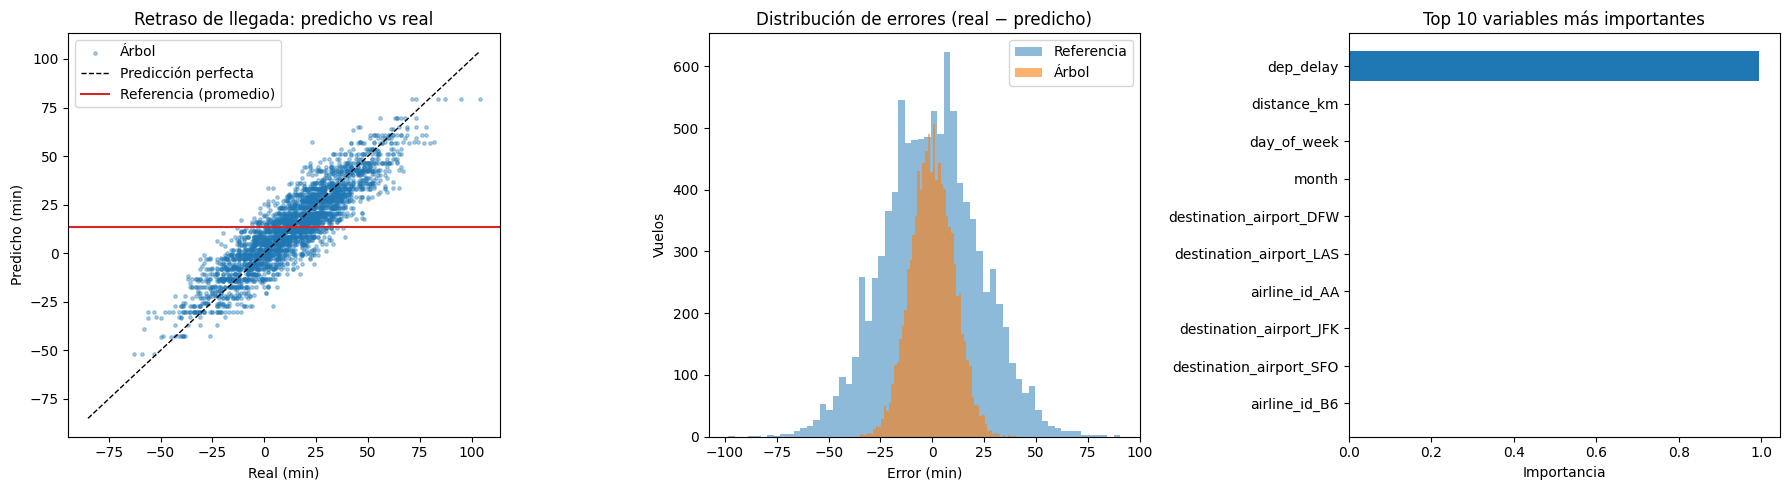

In [0]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Predicho vs real
muestra = np.random.RandomState(SEED).choice(len(y_test), size=min(3000, len(y_test)), replace=False)
axes[0].scatter(y_test.values[muestra], pred_tree[muestra], s=6, alpha=0.35, label="Árbol")
lims = [min(y_test.min(), pred_tree.min()), max(y_test.max(), pred_tree.max())]
axes[0].plot(lims, lims, "k--", lw=1, label="Predicción perfecta")
axes[0].axhline(baseline_value, color="tab:red", lw=1.5, label="Referencia (promedio)")
axes[0].set(title="Retraso de llegada: predicho vs real", xlabel="Real (min)", ylabel="Predicho (min)")
axes[0].legend()

# 2) Distribución de errores
axes[1].hist(y_test - pred_baseline, bins=60, alpha=0.5, label="Referencia")
axes[1].hist(y_test - pred_tree, bins=60, alpha=0.6, label="Árbol")
axes[1].set(title="Distribución de errores (real − predicho)", xlabel="Error (min)", ylabel="Vuelos")
axes[1].legend()

# 3) Importancia de variables
nombres = modelo.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(modelo.named_steps["tree"].feature_importances_, index=nombres)
importancias = importancias.sort_values(ascending=False).head(10)[::-1]
axes[2].barh([n.split("__")[-1] for n in importancias.index], importancias.values)
axes[2].set(title="Top 10 variables más importantes", xlabel="Importancia")

plt.tight_layout()
plt.show()

### Interpretación

- **El árbol supera ampliamente a la referencia**: reduce el MAE de unos 18 a unos 8 minutos y el RMSE de unos 23 a unos 10 (≈ 55 % menos error en ambas métricas). La referencia ignora toda la información del vuelo, por eso su error es igual a la dispersión natural de los retrasos.
- **`dep_delay` es la variable dominante**: concentra casi toda la importancia del árbol. Un avión que sale tarde casi siempre llega tarde, y la nube de puntos sigue la diagonal de predicción perfecta.
- **El resto de variables aporta muy poco**: aerolínea, aeropuertos, distancia y calendario apenas aparecen en la importancia. El error restante (≈ 8 minutos) corresponde a variación que estas variables no explican, como el clima o la congestión del día.
- **Los errores del árbol están centrados en 0** y son mucho más estrechos que los de la referencia, así que el modelo no tiende a sobrestimar ni a subestimar.
- **Limitación práctica**: como el modelo depende del retraso de salida, sirve para estimar la hora de llegada **una vez que el avión ya despegó**, no para anticipar retrasos días antes. Para eso habría que quitar `dep_delay` y añadir variables como clima o historial de la ruta.

#### 6.6 Guardar el modelo, las predicciones y las métricas, 
####Registrar en MLflow

In [0]:
predicciones = pd.DataFrame({
    "flight_id": ids_test.values,
    "airline_id": X_test["airline_id"].values,
    "origin_airport": X_test["origin_airport"].values,
    "destination_airport": X_test["destination_airport"].values,
    "dep_delay": X_test["dep_delay"].values,
    "arr_delay_real": y_test.values,
    "pred_baseline": pred_baseline,
    "pred_tree": pred_tree,
})
predicciones["error_tree"] = predicciones["arr_delay_real"] - predicciones["pred_tree"]
predicciones.head()

,flight_id,airline_id,origin_airport,destination_airport,dep_delay,arr_delay_real,pred_baseline,pred_tree,error_tree
0,FL-147723,UA,JFK,DEN,-8,-14,13.403173,-2.890736,-11.109264
1,FL-118484,DL,JFK,SFO,3,23,13.403173,8.376168,14.623832
2,FL-142309,WN,ATL,ORD,-10,1,13.403173,-5.611664,6.611664
3,FL-112850,B6,LAX,LAS,24,47,13.403173,28.795756,18.204244
4,FL-111177,WN,JFK,ATL,-10,-11,13.403173,-5.075949,-5.924051


In [0]:
mlflow.set_registry_uri("databricks-uc")

with mlflow.start_run(run_name="arrival_delay_decision_tree") as run:
    # Parámetros y datos
    mlflow.log_params(TREE_PARAMS)
    mlflow.log_params({"features_num": ",".join(NUM_FEATURES),
                       "features_cat": ",".join(CAT_FEATURES),
                       "target": TARGET, "test_size": 0.2,
                       "train_rows": len(X_train), "test_rows": len(X_test),
                       "source_table": FEATURES_TABLE})
    # Métricas
    mlflow.log_metrics({"baseline_mae": m_base["MAE"], "baseline_rmse": m_base["RMSE"],
                        "tree_mae": m_tree["MAE"], "tree_rmse": m_tree["RMSE"]})
    # Gráficos y tabla de resultados
    mlflow.log_figure(fig, "predicciones_vs_reales.png")
    mlflow.log_table(resultados, "comparacion_modelos.json")
    # Modelo (se registra en Unity Catalog)
    firma = infer_signature(X_train, modelo.predict(X_train))
    mlflow.sklearn.log_model(modelo, artifact_path="model", signature=firma,
                             input_example=X_train.head(5),
                             registered_model_name=MODEL_NAME)
    run_id = run.info.run_id

print("Run de MLflow:", run_id)
print("Modelo registrado en Unity Catalog:", MODEL_NAME)

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/05 00:33:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-dcdc4017-31e4.cloud.databricks.com/ml/experiments/2462558112280834/models/m-ac5ba2d6b8c048e88c8ef

Uploading artifacts:   0%|          | 0/11 [00:00<?, ?it/s]

🔗 Created version '3' of model 'aerolinea_trabajo_final.ml.arrival_delay_tree': https://dbc-dcdc4017-31e4.cloud.databricks.com/explore/data/models/aerolinea_trabajo_final/ml/arrival_delay_tree/version/3?o=7474658025537115


Run de MLflow: 35f7ac24f06c4b20b84384b3b04e6c44
Modelo registrado en Unity Catalog: aerolinea_trabajo_final.ml.arrival_delay_tree


In [0]:
from pyspark.sql import functions as F

# Predicciones del conjunto de evaluación
(spark.createDataFrame(predicciones)
   .withColumn("mlflow_run_id", F.lit(run_id))
   .withColumn("prediction_timestamp", F.current_timestamp())
   .write.format("delta").mode("overwrite").option("overwriteSchema", "true")
   .saveAsTable(f"{CATALOG}.ml.arrival_delay_predictions"))

# Métricas de ambos modelos
(spark.createDataFrame(resultados.round(4))
   .withColumn("mlflow_run_id", F.lit(run_id))
   .withColumn("evaluated_at", F.current_timestamp())
   .write.format("delta").mode("append").option("mergeSchema", "true")
   .saveAsTable(f"{CATALOG}.ml.model_metrics"))

display(spark.table(f"{CATALOG}.ml.model_metrics"))

modelo,MAE,RMSE,mejora_MAE_pct,mejora_RMSE_pct,mlflow_run_id,evaluated_at
Referencia (promedio),18.326,22.979,0.0,0.0,35f7ac24f06c4b20b84384b3b04e6c44,2026-11-05T00:33:36.171Z
Árbol de regresión,8.1932,10.2228,55.2918,55.5123,35f7ac24f06c4b20b84384b3b04e6c44,2026-11-05T00:33:36.171Z
Referencia (promedio),18.326,22.979,0.0,0.0,7bbd50da8f694409b85c3aec0ba7344d,2026-11-04T23:54:37.263Z
Árbol de regresión,8.1932,10.2228,55.2918,55.5123,7bbd50da8f694409b85c3aec0ba7344d,2026-11-04T23:54:37.263Z
Referencia (promedio),18.326,22.979,0.0,0.0,162a982f7de14cb29dabf5b8daf61944,2026-11-04T03:57:29.706Z
Árbol de regresión,8.1932,10.2228,55.2918,55.5123,162a982f7de14cb29dabf5b8daf61944,2026-11-04T03:57:29.706Z


In [0]:
# Comprobación: cargar el modelo registrado y predecir algunos vuelos
modelo_cargado = mlflow.sklearn.load_model(f"runs:/{run_id}/model")
X_test.head(5).assign(arr_delay_real=y_test.head(5).values,
                      prediccion=modelo_cargado.predict(X_test.head(5)).round(1))

,dep_delay,distance_km,month,day_of_week,airline_id,origin_airport,destination_airport,arr_delay_real,prediccion
47439,-8,3270.18,5,3,UA,JFK,DEN,-14,-2.9
5146,3,3872.07,5,5,DL,JFK,SFO,23,8.4
29621,-10,1536.92,5,6,WN,ATL,ORD,1,-5.6
10172,24,2003.63,3,7,B6,LAX,LAS,47,28.8
644,-10,617.99,2,4,WN,JFK,ATL,-11,-5.1
